In [55]:
# 1. Import Libraries
import numpy as np
import keras
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras import layers





In [56]:

# 2. Load MNIST Dataset

(x_train, _), (x_test, y_test) = mnist.load_data()


In [57]:
# 3. Normalize and Flatten Images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

In [58]:
# 4. Add Noise
noise = 0.15

x_train_noisy = np.clip(x_train + noise * np.random.normal(size=x_train.shape), 0, 1)

x_test_noisy = np.clip(x_test + noise * np.random.normal(size=x_test.shape), 0, 1)

# Select One Image of Each Digit (0 to 9)
indices = [np.where(y_test == i)[0][0] for i in range(10)]

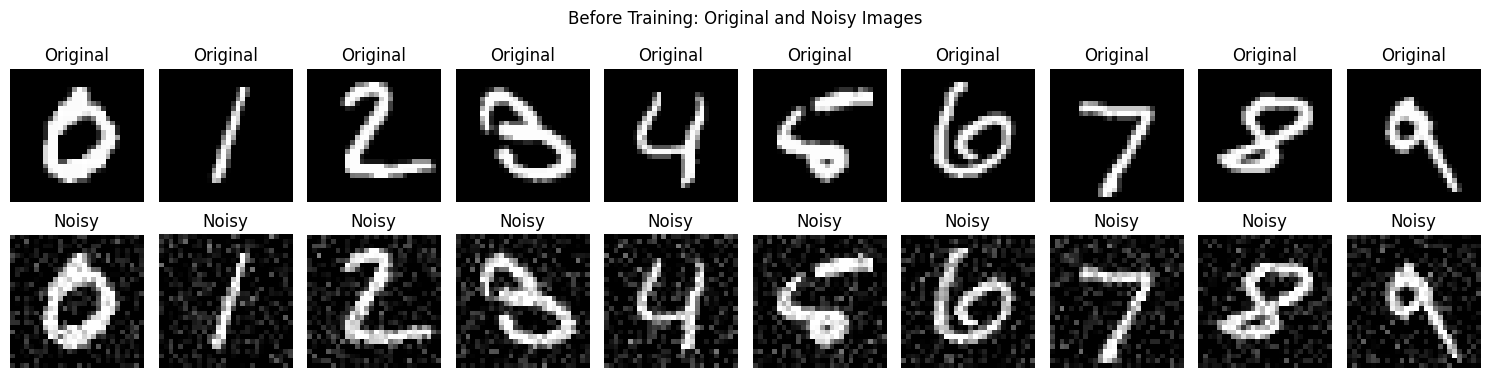

In [68]:
# 5. Display Original and Noisy Images BEFORE Training
plt.figure(figsize=(15, 4))

for i, idx in enumerate(indices):

    plt.subplot(2, 10, i+1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 10, i+11)
    plt.imshow(x_test_noisy[idx].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

plt.suptitle("Before Training: Original and Noisy Images")
plt.tight_layout()
plt.show()

In [59]:
# 5. Build Autoencoder with Sparsity Constraint
input_img = keras.Input(shape=(784,))

encoded = layers.Dense(256, activation="relu",activity_regularizer=keras.regularizers.l1(1e-6))(input_img)

decoded = layers.Dense(784, activation="sigmoid")(encoded)

autoencoder = keras.Model(input_img, decoded)

In [60]:
# 6. Compile Model
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)


In [61]:
# 7. Train Model
autoencoder.fit(
    x_train_noisy, x_train,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - loss: 0.3233 - val_loss: 0.1473
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - loss: 0.1406 - val_loss: 0.1237
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - loss: 0.1223 - val_loss: 0.1150
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - loss: 0.1144 - val_loss: 0.1100
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.1096 - val_loss: 0.1065
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.1064 - val_loss: 0.1039
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step - loss: 0.1038 - val_loss: 0.1017
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - loss: 0.1014 - val_loss: 0.0999
Epoch 9/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.0998 - val_loss: 0.0984
Epoch 10/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0982 - val_loss: 0.0971
Epoch 11/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.0971 - val_loss: 0.0959
Epoch 12/50
235/235 ━━━━━━━━━━━━━━━━━━━━

In [62]:
# 8. Reconstruct Images
denoised = autoencoder.predict(x_test_noisy[indices], verbose=0)

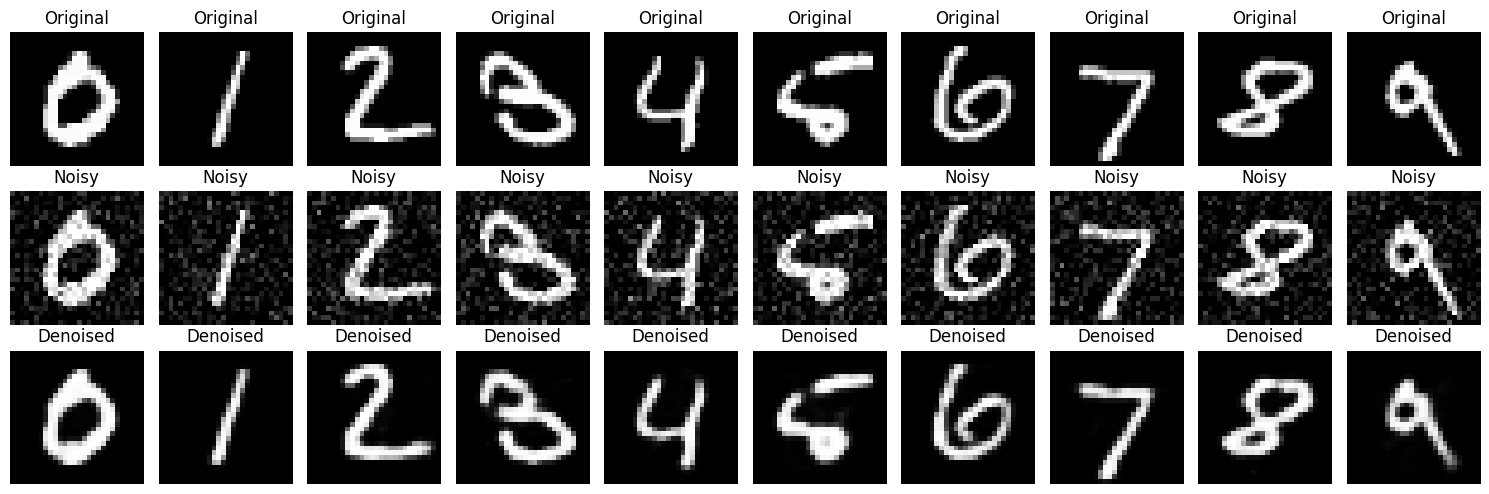

In [63]:
# 9. Display Original, Noisy and Denoised Images
plt.figure(figsize=(15, 5))

for i, idx in enumerate(indices):

    plt.subplot(3, 10, i+1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(3, 10, i+11)
    plt.imshow(x_test_noisy[idx].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    plt.subplot(3, 10, i+21)
    plt.imshow(denoised[i].reshape(28, 28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
1. What is an Autoencoder?
An autoencoder is a type of neural network that learns to compress input data and reconstruct it. It is commonly used for image denoising and data compression.
2. What is image denoising?
Image denoising is the process of removing unwanted noise from an image to obtain a clearer image.
3. What is the MNIST dataset?
MNIST is a dataset containing handwritten digit images from 0 to 9. Each image is of size 28 × 28 pixels.
4. Why do we use an Autoencoder?
We use an autoencoder to learn image features and reconstruct clean images from noisy inputs.
5. What are the main components of an Autoencoder?
An autoencoder has two main components:
- Encoder – Compresses the input image.
- Decoder – Reconstructs the original image.
6. What is the purpose of adding noise?
Noise is added to images to train the model to remove unwanted disturbances and reconstruct clean images.
7. Which type of noise is used in your code?
We use Gaussian noise, which adds random values to image pixels to create noisy images.
8. Why do we use Normalization?
Normalization converts pixel values from 0–255 into 0–1. It helps the model train more effectively.
9. Why do we use Flatten?
Flatten converts a 28 × 28 image into a one-dimensional array containing 784 values.
10. What is the purpose of the Encoder?
The encoder compresses the input image into a smaller representation containing important image features.
11. What is the purpose of the Decoder?
The decoder reconstructs the clean image from the encoded representation.
12. Why do we use ReLU activation?
ReLU introduces non-linearity into the network and helps it learn image features.
13. Why do we use Sigmoid activation?
Sigmoid produces output values between 0 and 1, which is suitable for normalized image pixels.
14. What is a Sparsity Constraint?
A sparsity constraint encourages most values in the encoded representation to remain close to zero.
15. What is L1 Regularization?
L1 regularization adds a penalty based on the absolute values of encoded activations. It helps create sparse representations.
16. Which optimizer is used in your code?
We use the Adam optimizer. It updates the model weights to minimize the loss.
17. Which loss function is used?
We use Binary Crossentropy to measure the difference between the reconstructed image and the original clean image.
18. Why do we use epochs=50?
Epochs represent the number of times the model passes through the complete training dataset. Here, we train for 50 epochs.
19. What is the purpose of Batch Size?
Batch size determines how many images are processed before updating the model weights. In our code, it is 256.
20. What is the difference between Original, Noisy and Denoised images?
- Original: The clean input image.
- Noisy: The image after adding Gaussian noise.
- Denoised: The reconstructed image after removing noise using the trained autoencoder.